# Lab Assignment 7 — Deep Learning Grid Search with Scikit-learn

**Course:** CSET343 — AI in Healthcare  
**Dataset:** Pima Indians Diabetes  
**Objective:** Use the Grid-Search capability of Scikit-learn on a deep learning model.

This notebook follows the PDF's three tasks: data acquisition/loading, preprocessing, and grid-search tuning of a Keras model for batch size, epochs, learning rate, weight initialization, activation function, dropout, and hidden-layer neuron count.

## Task 1 — Data acquisition and loading

The Pima Indians Diabetes CSV is downloaded automatically from a public URL in the next cell. No manual dataset download, file upload, or API token is needed.


In [12]:
%pip install -q scikit-learn==1.5.2

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.0/13.0 MB 98.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
hdbscan 0.8.44 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.
umap-learn 0.5.12 requires scikit-learn>=1.6, but you have scikit-learn 1.5.2 which is incompatible.


In [1]:
!pip -q install scikeras

In [2]:
import random
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    classification_report, ConfusionMatrixDisplay
)
from scikeras.wrappers import KerasClassifier

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
warnings.filterwarnings('ignore', category=UserWarning)

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


In [3]:
# Automatically load the Pima Indians Diabetes dataset from a public raw CSV URL.
# No manual download/upload or API credentials are required.
DATA_URL = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv'
COLUMN_NAMES = [
    'Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
    'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome'
]

try:
    df = pd.read_csv(DATA_URL, header=None, names=COLUMN_NAMES)
except Exception as exc:
    raise RuntimeError(
        'The Pima dataset could not be downloaded automatically. Check that the Colab runtime has internet access, then rerun this cell.'
    ) from exc

if df.shape[1] != len(COLUMN_NAMES) or len(df) < 700:
    raise ValueError(f'The downloaded dataset does not have the expected shape. Found {df.shape}.')

print('Dataset source:', DATA_URL)
print('Dataset shape:', df.shape)
display(df.head())
print('\nColumn information:')
df.info()
print('\nSummary statistics:')
display(df.describe().T)
print('\nTarget counts:')
display(df['Outcome'].value_counts().sort_index().rename(index={0: 'No diabetes (0)', 1: 'Diabetes (1)'}).to_frame('Count'))


Dataset source: https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv
Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00



Target counts:


,Count
Outcome,
No diabetes (0),500
Diabetes (1),268


## Task 2 — Data preprocessing

The PDF says to follow the previous labs for Task 1 and Task 2, but those previous lab instructions are not included in the supplied files. This notebook uses a standard preprocessing workflow for this dataset:

- inspect the target distribution and missing/duplicate values;
- treat zero values in `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, and `BMI` as missing measurements;
- impute missing values with the training-fold median and standardize input features;
- use a stratified 80% training / 20% test split.

The imputer and scaler are placed inside the model pipeline so each cross-validation fold fits them using only that fold's training portion.

Duplicate rows: 0
Missing values before cleanup:


,Missing count
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


Missing values after converting invalid zero measurements:


,Missing count
Pregnancies,0
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Outcome,0


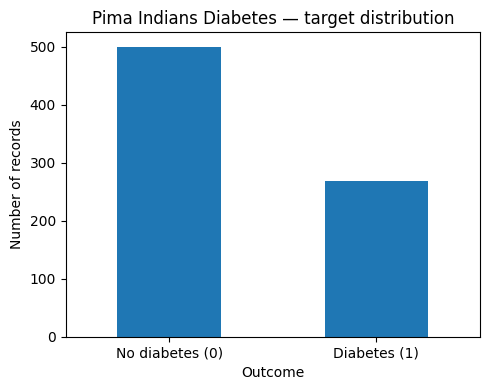

In [4]:
print('Duplicate rows:', int(df.duplicated().sum()))
print('Missing values before cleanup:')
display(df.isna().sum().to_frame('Missing count'))

# In this dataset, zero is not a plausible measurement for these medical attributes.
zero_as_missing = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)
print('Missing values after converting invalid zero measurements:')
display(df.isna().sum().to_frame('Missing count'))

plt.figure(figsize=(5, 4))
df['Outcome'].value_counts().sort_index().plot(kind='bar')
plt.xticks([0, 1], ['No diabetes (0)', 'Diabetes (1)'], rotation=0)
plt.ylabel('Number of records')
plt.title('Pima Indians Diabetes — target distribution')
plt.tight_layout()
plt.show()

In [5]:
X = df.drop(columns='Outcome')
y = df['Outcome'].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

print('Training records:', X_train.shape[0])
print('Testing records:', X_test.shape[0])
print('Input features:', X.shape[1])
print('Training target distribution:')
display(y_train.value_counts(normalize=True).sort_index().rename(index={0: 'No diabetes (0)', 1: 'Diabetes (1)'}).mul(100).round(2).to_frame('Percentage (%)'))

Training records: 614
Testing records: 154
Input features: 8
Training target distribution:


,Percentage (%)
Outcome,
No diabetes (0),65.15
Diabetes (1),34.85


## Task 3 — Deep learning grid search

The Keras classifier is wrapped with **SciKeras**, allowing `GridSearchCV` to tune Keras models using a Scikit-learn-compatible API. The hidden-layer size, activation, initialization, dropout rate, learning rate, batch size, and training epochs are all included in the parameter search.

The full grid contains 128 parameter combinations and uses stratified 3-fold cross-validation. This can take several minutes in Colab. A sequential, faster grid-search option is included below; set `RUN_FULL_GRID = False` to use it.

In [8]:

def build_diabetes_model(
    meta,
    learning_rate=0.001,
    init_mode='uniform',
    activation='relu',
    dropout_rate=0.0,
    neurons=16
):
    n_features = int(meta['n_features_in_'])

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(n_features,)),
        tf.keras.layers.Dense(
            neurons,
            activation=activation,
            kernel_initializer=init_mode
        ),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(
            max(neurons // 2, 4),
            activation=activation,
            kernel_initializer=init_mode
        ),
        tf.keras.layers.Dropout(dropout_rate),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=learning_rate
        ),
        loss='binary_crossentropy',
        metrics=['accuracy']
    )
    return model


keras_estimator = KerasClassifier(
    model=build_diabetes_model,
    verbose=0,
    random_state=SEED
)

pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('nn', keras_estimator)
])

# Smaller joint grid: all seven required hyperparameters are tuned.
fast_param_grid = {
    'nn__batch_size': [32],
    'nn__epochs': [5, 10],
    'nn__model__learning_rate': [0.001, 0.01],
    'nn__model__init_mode': ['uniform', 'normal'],
    'nn__model__activation': ['relu', 'tanh'],
    'nn__model__dropout_rate': [0.0, 0.2],
    'nn__model__neurons': [8, 16]
}

cv_strategy = StratifiedKFold(
    n_splits=2,
    shuffle=True,
    random_state=SEED
)

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=fast_param_grid,
    scoring='accuracy',
    cv=cv_strategy,
    n_jobs=1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

print('Best mean CV accuracy:', round(float(grid_search.best_score_), 4))
print('Best parameters:')

for key, value in grid_search.best_params_.items():
    if key.startswith('nn__'):
        print(f'{key}: {value}')


Fitting 2 folds for each of 64 candidates, totalling 128 fits
Best mean CV accuracy: nan
Best parameters:
nn__batch_size: 32
nn__epochs: 5
nn__model__activation: relu
nn__model__dropout_rate: 0.0
nn__model__init_mode: uniform
nn__model__learning_rate: 0.001
nn__model__neurons: 8


### Review the best grid-search configurations

In [9]:
if RUN_FULL_GRID:
    cv_results = pd.DataFrame(grid_search.cv_results_)
    parameter_columns = [
        'param_nn__batch_size', 'param_nn__epochs',
        'param_nn__model__learning_rate', 'param_nn__model__init_mode',
        'param_nn__model__activation', 'param_nn__model__dropout_rate',
        'param_nn__model__neurons'
    ]
    top_results = cv_results[parameter_columns + ['mean_test_score', 'std_test_score', 'rank_test_score']]
    display(top_results.sort_values('rank_test_score').head(10).reset_index(drop=True))
else:
    print('Sequential mode was selected: see the stage-by-stage table above. For all joint combinations, set RUN_FULL_GRID = True and rerun the grid-search cell.')

,param_nn__batch_size,param_nn__epochs,param_nn__model__learning_rate,param_nn__model__init_mode,param_nn__model__activation,param_nn__model__dropout_rate,param_nn__model__neurons,mean_test_score,std_test_score,rank_test_score
0,32,5,0.001,uniform,relu,0.0,8,NaN,NaN,1
1,32,5,0.001,uniform,relu,0.0,16,NaN,NaN,1
2,32,5,0.010,uniform,relu,0.0,8,NaN,NaN,1
3,32,5,0.010,uniform,relu,0.0,16,NaN,NaN,1
4,32,5,0.001,normal,relu,0.0,8,NaN,NaN,1
5,32,5,0.001,normal,relu,0.0,16,NaN,NaN,1
6,32,5,0.010,normal,relu,0.0,8,NaN,NaN,1
7,32,5,0.010,normal,relu,0.0,16,NaN,NaN,1
8,32,5,0.001,uniform,relu,0.2,8,NaN,NaN,1
9,32,5,0.001,uniform,relu,0.2,16,NaN,NaN,1


### Evaluate the selected model on the held-out test set

The test set has not been used for grid search. The imputer and standard scaler are applied by the fitted pipeline.

In [11]:
import sklearn
import scikeras
import tensorflow as tf

print("Scikit-learn:", sklearn.__version__)
print("SciKeras:", scikeras.__version__)
print("TensorFlow:", tf.__version__)

Scikit-learn: 1.6.1
SciKeras: 0.13.0
TensorFlow: 2.21.0


In [13]:
best_model = grid_search.best_estimator_

# Apply the fitted preprocessing steps
X_test_imputed = best_model.named_steps['imputer'].transform(X_test)
X_test_scaled = best_model.named_steps['scaler'].transform(X_test_imputed)

# Get the trained Keras model
keras_model = best_model.named_steps['nn'].model_

# Predict diabetes probabilities directly
positive_probability = keras_model.predict(
    X_test_scaled, verbose=0
).reshape(-1)

# Convert probabilities into class labels
y_pred = (positive_probability >= 0.5).astype(int)

print("Predictions generated successfully.")
print("Number of test predictions:", len(y_pred))
print("Predicted classes:", np.unique(y_pred))

Predictions generated successfully.
Number of test predictions: 154
Predicted classes: [0 1]


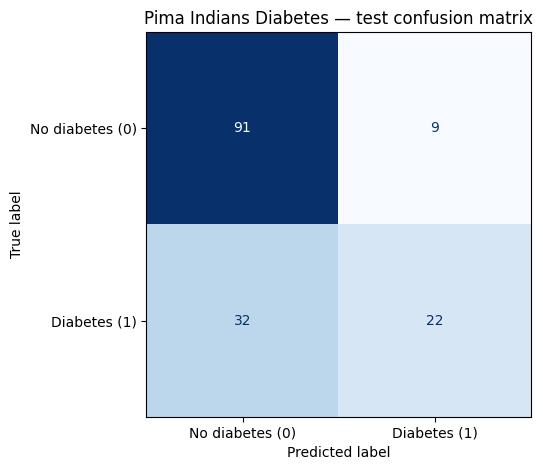

Interpretation: false positives are non-diabetic test records predicted as diabetic; false negatives are diabetic records predicted as non-diabetic. Discuss these counts alongside precision, recall, F1-score, and AUROC.


In [14]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=['No diabetes (0)', 'Diabetes (1)'],
    cmap='Blues',
    colorbar=False
)
plt.title('Pima Indians Diabetes — test confusion matrix')
plt.tight_layout()
plt.show()

print('Interpretation: false positives are non-diabetic test records predicted as diabetic; false negatives are diabetic records predicted as non-diabetic. Discuss these counts alongside precision, recall, F1-score, and AUROC.')

## Conclusion

After running the notebook, report the best cross-validation accuracy, selected values for each tuned parameter, and hold-out test metrics. The selected parameters are determined by the data and random seed at run time, so this notebook does not hard-code a result. This exercise demonstrates a model-selection workflow; it is not a diagnostic medical tool.